# 03 - Explaining the model and choosing who gets a coupon

1. **Why** does the model call a household risky? (logistic coefficients, then SHAP)
2. **Who** should get a coupon: the households most likely to churn, or the ones we would lose the most sales on?

Run `python -m src.train` first: it writes the final model and the validation- and test-week scores.

In [1]:
import os, sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Run from the repo root whether the notebook is opened from notebooks/ or from the root
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

from src.config import FIGURES_DIR
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 3)

In [2]:
import joblib
from src.config import FINAL_MODEL, MODEL_PATH, PROCESSED_DIR
from src.features import FEATURES

model = joblib.load(MODEL_PATH)                              # final model, refit on all labelled snapshots
valid = pd.read_csv(PROCESSED_DIR / "valid_scores.csv")      # week 86, scored by models trained on weeks 30..78
test = pd.read_csv(PROCESSED_DIR / "test_scores.csv")        # week 94, scored by models trained on weeks 30..86
print(f"final model: {FINAL_MODEL} | test households: {len(test):,} | test churn rate: {test['churn'].mean():.1%}")

final model: logistic | test households: 2,316 | test churn rate: 8.2%


## 1. Which features drive the risk? Logistic coefficients

**Question:** what has the model learned, in words a store manager would understand?

The features were standardized (notebook 02), so each coefficient is the change in the **log-odds** of churn for one standard
deviation (SD) more of that feature, with the other features held fixed. `exp(coef)` is the **odds ratio**:
below 1 = less risk, above 1 = more risk.

In [3]:
from src.train import OTHER

clf = model[-1]
coef = pd.Series(clf.coef_[0], index=model["prep"].get_feature_names_out())
one_sd = pd.Series(model["prep"].named_transformers_["other"].scale_, index=OTHER)   # skewed features: SD of log1p(x)
coefficients = pd.DataFrame({"coef": coef, "odds_ratio": np.exp(coef), "1 SD in original units": one_sd})
coefficients = coefficients.reindex(coef.abs().sort_values(ascending=False).index)
coefficients

,coef,odds_ratio,1 SD in original units
active_weeks_12w,-0.752,0.472,3.594
active_weeks_4w,-0.638,0.528,1.386
active_share,-0.477,0.621,0.267
sales_12w,-0.252,0.777,NaN
baskets_12w,0.240,1.271,NaN
coupon_items_12w,-0.194,0.824,NaN
recency_weeks,0.104,1.110,2.249
avg_basket_value_12w,0.048,1.049,NaN
discount_share_12w,-0.045,0.956,0.072
trend_4w_vs_12w,0.021,1.022,0.180


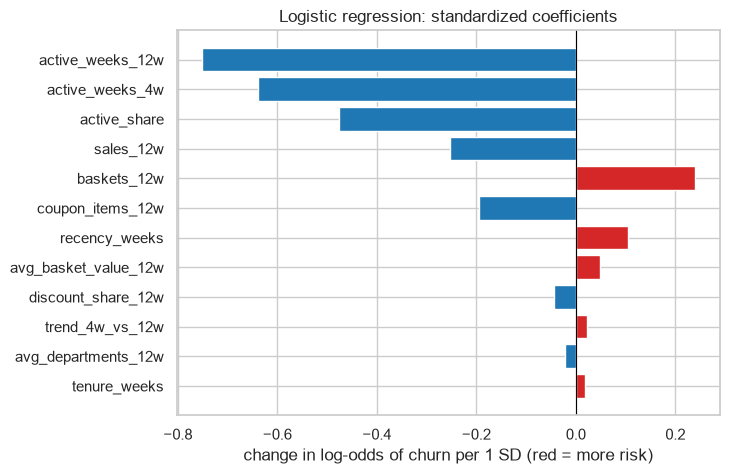

In [4]:
fig, ax = plt.subplots(figsize=(7, 5))
c = coefficients["coef"].iloc[::-1]
ax.barh(c.index, c.values, color=np.where(c.values > 0, "tab:red", "tab:blue"))
ax.axvline(0, c="black", lw=0.8)
ax.set(title="Logistic regression: standardized coefficients", xlabel="change in log-odds of churn per 1 SD (red = more risk)")
fig.savefig(FIGURES_DIR / "logistic_coefficients.png", dpi=120, bbox_inches="tight")
plt.show()

**How to read it** (odds ratios from the table, per 1 SD more of the feature):
* `active_weeks_12w`: about 3.6 more purchase weeks out of the last 12 multiply the odds of churn by **0.47**, so roughly halve them.
* `active_weeks_4w`: about 1.4 more purchase weeks out of the last 4 multiply the odds by **0.53**.
* `active_share`: buying in a bigger share of the weeks since the first purchase (+0.27) multiplies the odds by **0.62**.
* `sales_12w`: bigger recent spenders churn less (odds x **0.78** per SD of log sales).

**Careful with correlated features.** A coefficient is the effect *with the other features held fixed*. `recency_weeks` looks weak
(odds x 1.11) only because its information is already in `active_weeks_4w` (correlation -0.73: a household silent for 4+ weeks has
`active_weeks_4w` = 0). `baskets_12w` gets a positive sign for the same reason (correlation 0.69 with `active_weeks_12w`).
So the frequency features should be read as one group, not one by one.

**So what:** households that buy **often and regularly** are safe; the risk rises when their purchase weeks thin out.
That is a simple message a store manager can check and act on.

## 2. SHAP: the same story, household by household

**Question:** which features push the risk of each household up or down?

SHAP splits each prediction into one contribution per feature (in log-odds). For a linear model this is simply
**coefficient x (value - average value)**, so it must agree with the table above: the code checks it.
We explain the **final model** on the households it actually scores: those at risk in the latest week of the data.

In [5]:
import warnings
warnings.filterwarnings("ignore", message="IProgress not found")   # harmless message from the shap import
import shap
from src.features import build_scoring_table, load_inputs

weekly, _ = load_inputs()
latest = build_scoring_table(weekly, cutoff=int(weekly["week_no"].max()))
X = pd.DataFrame(model["prep"].transform(latest[FEATURES]), columns=model["prep"].get_feature_names_out())
explainer = shap.LinearExplainer(clf, shap.maskers.Independent(X, max_samples=len(X)))   # average = these households
sv = explainer(X)
by_hand = clf.coef_[0] * (X - X.mean())
print(f"{len(X):,} households | largest gap between SHAP and coef x (value - mean): {np.abs(sv.values - by_hand.to_numpy()).max():.1e}")

2,310 households | largest gap between SHAP and coef x (value - mean): 0.0e+00


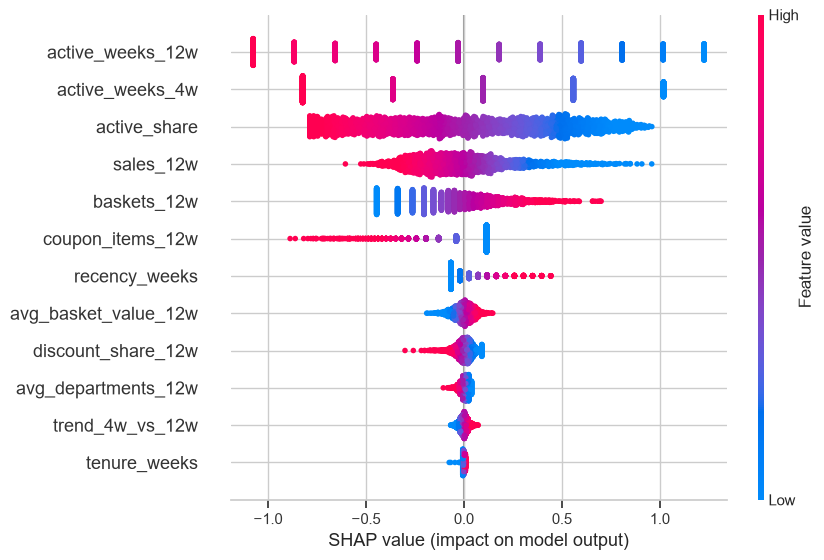

In [6]:
shap.plots.beeswarm(sv, max_display=12, show=False)
plt.gcf().savefig(FIGURES_DIR / "shap_beeswarm.png", dpi=120, bbox_inches="tight")
plt.show()

How to read the beeswarm: each dot is one household; red = high feature value, blue = low. The blue dots of `active_weeks_12w`
sit on the right: few purchase weeks raise the risk. Values are on the standardized / log scale used inside the pipeline.

**So what:** SHAP puts the same features on top as the coefficients (`active_weeks_12w`, `active_weeks_4w`, `active_share`, then spend),
because for a linear model it is the coefficient times how far the household is from the average.
The coefficient table is the main explanation; SHAP adds the view of each single household.

## 3. Who should get a coupon?

**Question:** with a budget of 10% of the households, should we target the most likely churners, or the ones we would lose the most sales on?

The same predictions can be ranked in two ways:
* **by churn risk**: the churn probability;
* **by expected sales lost** = churn probability x `sales_12w`: losing a big spender costs the store more than losing a small one.

For each budget (top 5%, 10%, ...) we count the real churners reached and their **sales at risk** (what those churners spent
in the last 12 weeks). The scores come from models trained **before** the week they score (see `src/train.py`).

In [7]:
from src.business import targeting_table

y, sales = test["churn"].to_numpy(), test["sales_12w"].to_numpy()
risk = test[f"score_{FINAL_MODEL}"].to_numpy()
print(f"median sales in the last 12 weeks: churners {np.median(sales[y == 1]):.0f} vs non-churners {np.median(sales[y == 0]):.0f}")
by_risk = targeting_table(y, risk, sales)
by_value = targeting_table(y, risk * sales, sales)
by_risk

median sales in the last 12 weeks: churners 65 vs non-churners 336


,share_targeted,households,churners_reached,share_of_all_churners,sales_at_risk_reached,share_of_sales_at_risk
0,0.05,115,44,0.233,1216.35,0.049
1,0.10,231,82,0.434,3699.45,0.148
2,0.20,463,133,0.704,8146.56,0.327
3,0.30,694,156,0.825,11771.44,0.472
4,0.50,1158,175,0.926,18138.30,0.728
5,1.00,2316,189,1.000,24931.74,1.000


In [8]:
by_value

,share_targeted,households,churners_reached,share_of_all_churners,sales_at_risk_reached,share_of_sales_at_risk
0,0.05,115,23,0.122,5166.80,0.207
1,0.10,231,40,0.212,8807.44,0.353
2,0.20,463,74,0.392,13535.75,0.543
3,0.30,694,101,0.534,15659.24,0.628
4,0.50,1158,138,0.730,21086.71,0.846
5,1.00,2316,189,1.000,24931.74,1.000


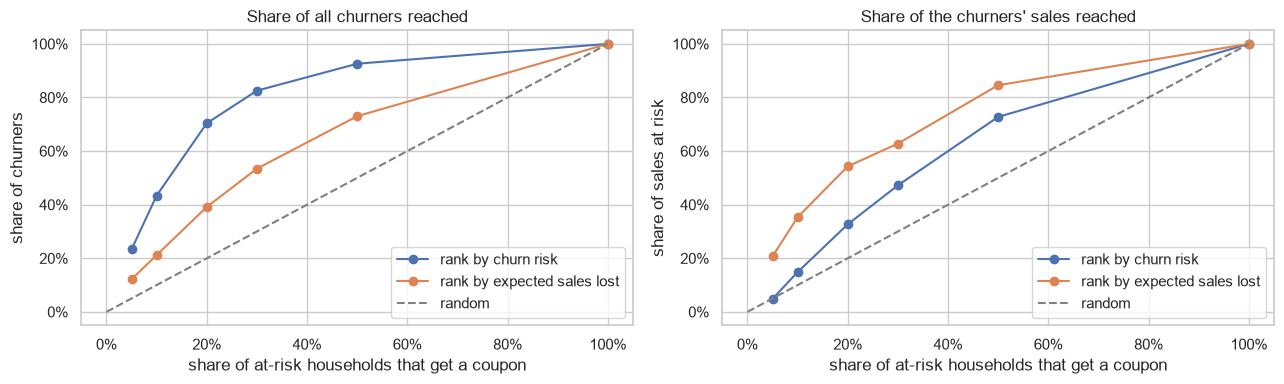

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for t, label in [(by_risk, "rank by churn risk"), (by_value, "rank by expected sales lost")]:
    axes[0].plot(t["share_targeted"], t["share_of_all_churners"], marker="o", label=label)
    axes[1].plot(t["share_targeted"], t["share_of_sales_at_risk"], marker="o", label=label)
axes[0].set(title="Share of all churners reached", ylabel="share of churners")
axes[1].set(title="Share of the churners' sales reached", ylabel="share of sales at risk")
for ax in axes:
    ax.plot([0, 1], [0, 1], ls="--", c="grey", label="random")
    ax.set(xlabel="share of at-risk households that get a coupon")
    ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
    ax.legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "targeting_curve.png", dpi=120, bbox_inches="tight")
plt.show()

**Trade-off (test week):** ranking by risk reaches more churners (left), ranking by expected sales lost reaches more of the
**sales** that would be lost (right).

### Does the model really help this decision?

Maybe "big spenders first" is enough and the model adds nothing. We compare four rankings, all with the same budget (10%):
* **churn risk** and **risk x sales** from the model;
* **recency rule x sales**: the simple "longest silence first" rule instead of the model's risk;
* **sales only**: the biggest spenders first.

In [10]:
from src.business import compare_rankings

rankings = {
    "churn risk (model)": risk,
    "risk x sales (model)": risk * sales,
    "recency rule x sales (no model)": test["score_recency_rule"].to_numpy() * sales,
    "sales only (no model)": sales,
}
compare_rankings(y, rankings, sales)

,households,churners_reached,share_of_all_churners,share_of_sales_at_risk
churn risk (model),231.0,82.0,0.434,0.148
risk x sales (model),231.0,40.0,0.212,0.353
recency rule x sales (no model),231.0,24.0,0.127,0.246
sales only (no model),231.0,2.0,0.011,0.130


**So what:** ranking by **risk x sales** reaches the largest share of the sales at risk. "Sales only" is barely better than
random (big spenders rarely churn). The model is compared with the rule on both weeks in the next version of this section.

## 4. The coupon list for the latest week

`python -m src.predict` scores the households at risk in the last week of the data (week 102) with the saved final model
and writes the top 10% by expected sales lost to `reports/coupon_list.csv`.

In [11]:
from src.predict import main as predict
predict([])
pd.read_csv("reports/coupon_list.csv").head(10)

Week 102: 2,310 households at risk -> coupon list of the top 10% (231 households)
mean churn probability in the list 16.9% vs 7.5% for all at-risk households
Wrote reports/coupon_list.csv


,household_key,churn_probability,sales_12w,expected_sales_lost,recency_weeks,active_weeks_12w
0,1016,0.253,508.09,128.325,8,2.0
1,2042,0.219,466.85,102.108,4,2.0
2,1702,0.246,402.34,98.872,8,3.0
3,910,0.341,285.05,97.271,10,1.0
4,2251,0.255,340.04,86.786,7,2.0
5,149,0.112,752.99,84.710,8,4.0
6,1629,0.367,228.46,83.753,7,1.0
7,1196,0.165,452.75,74.753,4,4.0
8,1107,0.294,241.92,71.016,9,3.0
9,1657,0.238,296.79,70.690,4,4.0


## Conclusions and next steps
* The model relies on **how often and how regularly** a household buys (the coefficients and SHAP agree), which makes business sense.
* **Who** to target matters as much as the model: churners are mostly small spenders, so ranking by *risk x recent sales*
  reaches fewer churners but a much larger share of the sales at risk.
* The key unknown is **how many churners a coupon really keeps**: only an A/B test can measure it.